# code_013 · Sampling and data-generating processes

**Book:** Chapter 3, section 3.2. **Purpose:** an independent probability/statistics laboratory with synthetic populations and declared measurement models. No numerical result is evidence of structural safety, an empirical causal effect or production reliability.

Use the repository [quickstart](../README.md), select the [pinned environment](../requirements-lock.txt), restart and run every cell. Reference target: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, CPU only on macOS ARM64. All inputs, generators and helper definitions are here. Normal runs require no network, data files, API keys, GPU or private imports. Allow a minute for execution and 30–60 minutes for interpretation/exercises. Actual versions and time appear below and in [run evidence](../CHAPTER_03_EXECUTION.md).

Read predictions before output. Sampling assumptions, priors, numerical simulation budgets and decision margins have different roles; they are not all model hyperparameters. These are scoped concept laboratories, not full estimator-constructor guides. The [traceability guide](../CHAPTER_03_GUIDE.md) maps mechanisms and exercises, and the [stable registry](../CODE_EXAMPLES.md#code_013) preserves this ID. Synthetic algebra/population checks need no learned train/test split; any fitted prediction experiment below states its calibration and assessment boundaries.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import stats,special
from IPython.display import display
START=time.perf_counter();SEED=313
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 313


<a id="design"></a>
## Equal row counts, different independent information

Building rates p_g are iid Beta(2,18). Conditional on a building rate, its outcomes are independent Bernoulli(p_g). Across buildings, rates/outcomes are independent. The marginal population rate is .1 and within-building correlation is 1/21. This is a fully declared teaching population, not an empirical model of buildings. We use binomial counts to simulate member outcomes efficiently without materializing every row.

For G buildings with m outcomes each, variance of the grand mean is p(1-p)/(G*m) times [1+(m-1)*rho]. Derive it by expanding the variance of the sum, including within-building covariances. Effective row count describes variance for this estimand/model only.

**Predict:** which design has a narrower repeated-sample distribution: one building × 10,000 outcomes, or 100 buildings × 100 outcomes? Can one sampled building reveal arbitrary between-building variability by internal resampling?


,buildings,outcomes_per_building,rows,design_effect,effective_rows,theoretical_SE,empirical_SE
0,1,10000,10000,477.142857,20.958084,0.065531,0.066091
1,100,100,10000,5.714286,1750.000000,0.007171,0.007036


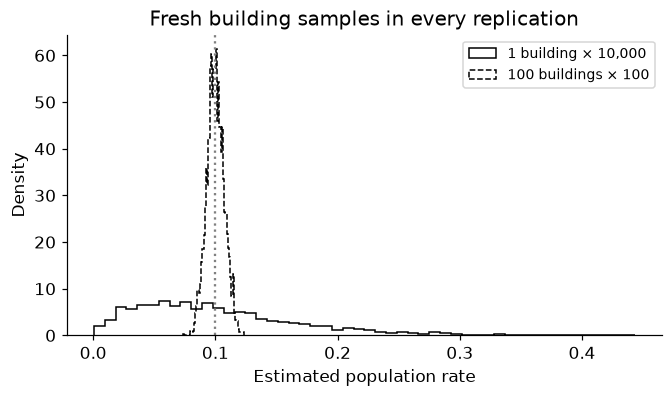

In [2]:
a,b=2.,18.;p=a/(a+b);rho=1/(a+b+1);repetitions=3000
var_p=a*b/((a+b)**2*(a+b+1))
assert np.isclose(var_p/(p*(1-p)),rho)
designs=[(1,10000),(100,100)];estimates={};rows=[]
for G,m in designs:
 latent=rng.beta(a,b,size=(repetitions,G));counts=rng.binomial(m,latent)
 sample_mean=counts.sum(1)/(G*m);effect=1+(m-1)*rho
 expected_se=np.sqrt(p*(1-p)/(G*m)*effect);empirical_se=sample_mean.std(ddof=1)
 estimates[G]=sample_mean
 assert abs(sample_mean.mean()-p)<4*expected_se/np.sqrt(repetitions)
 assert np.isclose(empirical_se,expected_se,rtol=.1)
 rows.append([G,m,G*m,effect,G*m/effect,expected_se,empirical_se])
comparison=pd.DataFrame(rows,columns=['buildings','outcomes_per_building','rows','design_effect','effective_rows','theoretical_SE','empirical_SE']);display(comparison)
fig,ax=plt.subplots(figsize=(6,3.5))
for G,style,label in [(1,'-','1 building × 10,000'),(100,'--','100 buildings × 100')]:ax.hist(estimates[G],bins=50,density=True,histtype='step',color='black',ls=style,label=label)
ax.axvline(p,color='.5',ls=':');ax.set(xlabel='Estimated population rate',ylabel='Density',title='Fresh building samples in every replication');ax.legend(fontsize=9);plt.show()
RESULTS['theoretical_SEs']=comparison.theoretical_SE.tolist();RESULTS['empirical_SEs']=comparison.empirical_SE.tolist();RESULTS['design_effects']=comparison.design_effect.tolist()


<a id="intervals"></a>
## Repeated intervals with known population variance

Using the simulator's *known* design variance and a normal critical value, construct approximate intervals for the 100-building design. Their repeated coverage is observable because the population mean is declared. The intervals are not inferred from the first sample alone. The normal approximation is justified here by many independent bounded building summaries, not by pretending 10,000 dependent rows are iid.

**Predict:** why must coverage be measured over fresh populations/samples rather than many bootstrap draws of one cohort? Would the same normal approximation necessarily work with one building and a skewed latent-rate distribution?


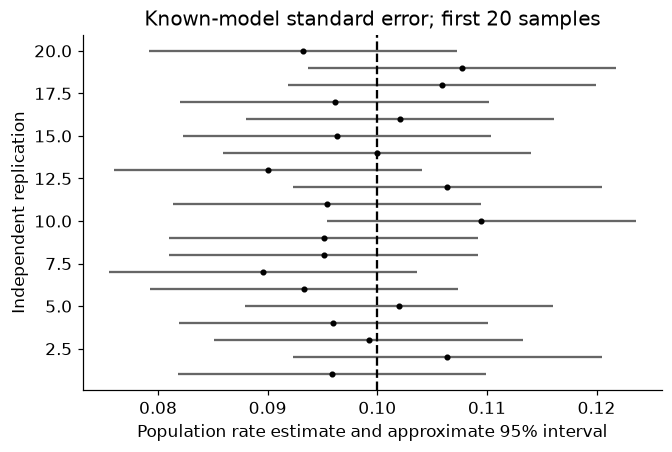

Repeated coverage over 3000 fresh samples: 0.95


In [3]:
z=stats.norm.ppf(.975);se=float(comparison.loc[comparison.buildings==100,'theoretical_SE'].iloc[0]);center=estimates[100]
lower=center-z*se;upper=center+z*se;coverage=np.mean((lower<=p)&(p<=upper))
assert .92<coverage<.98
fig,ax=plt.subplots(figsize=(6,4));idx=np.arange(1,21)
ax.hlines(idx,lower[:20],upper[:20],color='.4');ax.plot(center[:20],idx,'ko',ms=3);ax.axvline(p,color='black',ls='--')
ax.set(xlabel='Population rate estimate and approximate 95% interval',ylabel='Independent replication',title='Known-model standard error; first 20 samples');plt.show()
print('Repeated coverage over',repetitions,'fresh samples:',coverage)
RESULTS['known_model_interval_coverage']=float(coverage)


<a id="selection"></a>
## More selected records do not remove selection bias

A simplified observation rule samples exceeded-criterion members with probability .8 and other members with probability .2. In a real workflow selection may operate through warning signs, reporting or retrospective records; direct selection on the simulated outcome isolates the mechanism. The inspected population's event probability is .08/(.08+.18), not .1. Correcting selection generally needs known inclusion mechanisms and overlap; this example does not claim a universally valid correction.

**Predict:** do more observations under this same rule converge toward .1 or the selected-population probability?


In [4]:
outcome=rng.binomial(1,p,200000);inclusion=np.where(outcome==1,.8,.2);selected=rng.random(len(outcome))<inclusion
selected_rate=outcome[selected].mean();selected_theory=p*.8/(p*.8+(1-p)*.2)
assert abs(outcome.mean()-p)<.005 and abs(selected_rate-selected_theory)<.01
assert selected_rate>2*p
print('Population sample:',outcome.mean(),'selected sample:',selected_rate,'selected theory:',selected_theory)
RESULTS['selected_rate']=float(selected_rate);RESULTS['selected_rate_theory']=float(selected_theory)


Population sample: 0.09942 selected sample: 0.3080322530624903 selected theory: 0.30769230769230776


<a id="measurement"></a>
## Replication reduces random noise, not a fixed offset

Hold the latent deflection at 1 mm. Every reading has a fixed calibration offset .15 mm plus independent zero-mean noise with sd .2 mm. Running averages converge toward 1.15 mm rather than the latent response. In a real sensor, time dependence or drift can violate the independent-noise assumption too. A label misclassification process similarly changes what recorded outcomes mean.

**Predict:** can a tiny standard error around the measured mean establish that the sensor is accurate?


In [5]:
truth=1.;offset=.15;noise_sd=.2;readings=truth+offset+rng.normal(0,noise_sd,20000)
assert abs(readings.mean()-(truth+offset))<.01 and abs(readings.mean()-truth)>.1
print('Latent [mm]:',truth,'measured mean [mm]:',readings.mean(),'iid-noise SE [mm]:',noise_sd/np.sqrt(len(readings)))
RESULTS['biased_measurement_mean_mm']=float(readings.mean())
worksheet=pd.DataFrame([
 ['one building','new reading in this building','new-building population spread is unidentified from this single group'],
 ['100 independently sampled buildings','new comparable building','population inclusion and observation protocol still matter'],
 ['warning-selected inspections','selected members','selection enrichment is not population representativeness']
],columns=['sample','supported target under stated assumptions','remaining limitation'])
assert len(worksheet)==3;display(worksheet)


Latent [mm]: 1.0 measured mean [mm]: 1.1498345001021482 iid-noise SE [mm]: 0.001414213562373095


,sample,supported target under stated assumptions,remaining limitation
0,one building,new reading in this building,new-building population spread is unidentified...
1,100 independently sampled buildings,new comparable building,population inclusion and observation protocol ...
2,warning-selected inspections,selected members,selection enrichment is not population represe...


<a id="exercises"></a>
## Exercises and optional hints

1. Set rho to zero by using one fixed building probability. Verify that both equal-row designs then have the same theoretical variance.
2. Change the beta shape sum while preserving mean .1. Predict how within-building correlation and sampling spread change.
3. Increase readings per building at fixed building count; then increase building count at fixed reading count. Explain the different limits.
4. Introduce unequal cluster sizes and define whether the target is an equal-building or equal-member mean. Do not reuse the equal-size variance formula blindly.
5. Add temporal correlation or measurement drift; state why the iid running-average standard error no longer applies.

**Hints:** more independent groups can reveal between-group variation; a resampling method cannot create absent groups. Selection and measurement shifts are systematic process differences, not finite-sample noise. The known simulator variance is deliberately not claimed estimated from a single observed building.

**Troubleshooting:** compare sampling distributions of the same estimator/population, not raw outcome histograms. Monte Carlo errors fluctuate by seed; simulation budgets are numerical controls, not new scientific sample sizes. [NIST interval guidance](https://www.itl.nist.gov/div898/handbook/prc/section1/prc14.htm) explains repeated coverage, while the hierarchical variance used here is derived explicitly in the manuscript.


In [6]:
summary={'example_id':'code_013','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['population and observation units', 'hierarchical dependence', 'equal-row sampling designs', 'design effect and sampling distribution', 'selection bias', 'measurement offset'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["population and observation units", "hierarchical dependence", "equal-row sampling designs", "design effect and sampling distribution", "selection bias", "measurement offset"], "elapsed_seconds": 0.171, "example_id": "code_013", "hardware": "Darwin arm64 CPU", "results": {"biased_measurement_mean_mm": 1.1498345001021482, "design_effects": [477.1428571428571, 5.714285714285714], "empirical_SEs": [0.06609136998674232, 0.00703554200821363], "known_model_interval_coverage": 0.95, "selected_rate": 0.3080322530624903, "selected_rate_theory": 0.30769230769230776, "theoretical_SEs": [0.0655307997378768, 0.007171371656006362]}, "seed": 313, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
